# CLM email classification quality evaluation

This notebook converts the labeled Hugging Face email dataset into the typed `CLMClient.system_one` request format and measures six-class classification quality.

**Primary question:** How accurately and confidently does the real CLM model classify unseen emails as `forum`, `promotions`, `social_media`, `spam`, `updates`, or `verify_code`?

## Evaluation design

- Use only the published **test split** for quality reporting.
- Preserve the dataset's balanced class distribution with a stratified sample.
- Convert each row to a CLM state containing `subject` and `body`.
- Ask one typed six-way `Choice` question and retain the complete probability distribution.
- Report accuracy, macro/weighted F1, multiclass log loss, top-2 accuracy, per-class metrics, confusion, and confidence calibration.
- Save predictions incrementally so an interrupted run can resume.

> **Important:** Mock mode uses lexical character n-grams and is invalid for quality measurement. The health check below rejects a mock server. This run uses the complete 2,697-row held-out test split; use the training split for any criteria or fine-tuning iteration.

In [1]:
from __future__ import annotations

import json
import os
import platform
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from dotenv import load_dotenv
from IPython.display import display
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    log_loss,
    precision_recall_fscore_support,
    top_k_accuracy_score,
)
from sklearn.model_selection import train_test_split

from clm import CLMClient, CLMError, Choice

CLIENT_ROOT = Path(r"H:\masterswork\gitrash\CLM\CLMClient")
ENV_PATH = CLIENT_ROOT / ".env"
ARTIFACT_DIR = CLIENT_ROOT / "notebooks" / "artifacts"
CHECKPOINT_PATH = ARTIFACT_DIR / "clm_email_predictions.csv"

DATASET_ID = "jason23322/high-accuracy-email-classifier"
TEST_FILE = "test.json"
LABELS = ["forum", "promotions", "social_media", "spam", "updates", "verify_code"]
RANDOM_STATE = 42
EVALUATION_SAMPLE_SIZE = None  # Evaluate the complete held-out test split.
TEMPERATURE = 0.1
RUN_SMOKE_TEST = True
RUN_EVALUATION = True
CHECKPOINT_EVERY = 10

ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 120)

## Secure configuration

Secrets are loaded from `.env`; they are never printed or written to prediction artifacts. Required settings:

- `HUGGINGFACE_API_KEY`: read token with accepted access to the gated dataset.
- `CLM_BASE_URL`: CLM API endpoint.
- `CLM_MODEL`: model name, normally `clm-latest`.

In [2]:
if not ENV_PATH.is_file():
    raise FileNotFoundError(f"Configuration file not found: {ENV_PATH}")

load_dotenv(ENV_PATH)
HF_TOKEN = os.getenv("HUGGINGFACE_API_KEY")
CLM_BASE_URL = os.getenv("CLM_BASE_URL", "http://127.0.0.1:8700")
CLM_MODEL = os.getenv("CLM_MODEL", "clm-latest")

if not HF_TOKEN:
    raise RuntimeError(f"HUGGINGFACE_API_KEY is not configured in {ENV_PATH}")

print(f"Hugging Face token configured: {bool(HF_TOKEN)}")
print(f"CLM endpoint: {CLM_BASE_URL}")
print(f"CLM model: {CLM_MODEL}")

Hugging Face token configured: True
CLM endpoint: http://127.0.0.1:8700
CLM model: clm-latest


## Load and validate the labeled test data

The token is passed explicitly to pandas' Hugging Face filesystem. Schema and label checks fail loudly if the upstream dataset changes.

In [3]:
dataset_url = f"hf://datasets/{DATASET_ID}/{TEST_FILE}"
test_df = pd.read_json(dataset_url, storage_options={"token": HF_TOKEN})

expected_columns = {"id", "subject", "body", "text", "category", "category_id"}
missing_columns = expected_columns.difference(test_df.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_columns)}")

observed_labels = set(test_df["category"].dropna().unique())
if observed_labels != set(LABELS):
    raise ValueError(f"Unexpected labels: {sorted(observed_labels)}")
if test_df["id"].duplicated().any():
    raise ValueError("Test split contains duplicate IDs")
if test_df[["subject", "body", "category"]].isna().any().any():
    raise ValueError("Test split contains missing classification fields")

print(f"Test split: {len(test_df):,} rows x {len(test_df.columns)} columns")
display(test_df.groupby(["category_id", "category"]).size().rename("count").to_frame())

Test split: 2,697 rows x 6 columns


,,count
category_id,category,
0,forum,450
1,promotions,449
2,social_media,449
3,spam,449
4,updates,449
5,verify_code,451


## Select the held-out evaluation set

`EVALUATION_SAMPLE_SIZE = None` selects every row in the published test split. The stratified branch remains available only for quick development checks; it must not replace the full final holdout evaluation.

In [4]:
if EVALUATION_SAMPLE_SIZE is None:
    evaluation_df = test_df.copy()
elif not 0 < EVALUATION_SAMPLE_SIZE <= len(test_df):
    raise ValueError("EVALUATION_SAMPLE_SIZE must be None or between 1 and the test-set size")
else:
    evaluation_df, _ = train_test_split(
        test_df,
        train_size=EVALUATION_SAMPLE_SIZE,
        stratify=test_df["category"],
        random_state=RANDOM_STATE,
    )

evaluation_df = evaluation_df.sort_values("id").reset_index(drop=True)
print(f"Evaluation rows: {len(evaluation_df):,}")
display(evaluation_df["category"].value_counts().reindex(LABELS).rename("count").to_frame())

Evaluation rows: 2,697


,count
category,
forum,450
promotions,449
social_media,449
spam,449
updates,449
verify_code,451


## Convert email rows to typed CLM requests

`main.py` demonstrates the intended contract: pass structured state plus typed questions to `CLMClient.system_one`. Here, each email becomes a state object and the dataset taxonomy becomes one `Choice`. Criteria are descriptionsâ€”not examples from the test setâ€”to avoid label leakage.

In [5]:
CATEGORY_CRITERIA = {
    "forum": "Community forum conversations, discussion threads, group posts, replies, or member activity notifications.",
    "promotions": "Legitimate marketing, sales, discounts, product offers, newsletters, or commercial campaigns.",
    "social_media": "Notifications from social networks about follows, likes, mentions, direct activity, groups, or recommended content.",
    "spam": "Unsolicited, deceptive, suspicious, irrelevant, or low-quality bulk messages, including scams and phishing-like content.",
    "updates": "Operational, account, product, service, order, billing, travel, or informational status updates that are not verification codes.",
    "verify_code": "One-time passwords, authentication codes, account verification codes, login codes, or security confirmation tokens.",
}

CATEGORY_QUESTION = Choice(
    instructions=(
        "Classify this email into exactly one category. Use the subject and body together. "
        "Choose the most specific category represented by the email's primary purpose."
    ),
    criteria=CATEGORY_CRITERIA,
)

def email_state(row: pd.Series) -> dict[str, str]:
    return {
        "subject": str(row["subject"]).strip(),
        "body": str(row["body"]).strip(),
    }

display(pd.Series(email_state(evaluation_df.iloc[0]), name="CLM state").to_frame())

,CLM state
subject,AMA session: Tech CEO
body,"Thread ""Discussion 610"" moved from General to Support. Continue: wiki.site/page/789."


## Verify the real CLM server

A healthy HTTP response is not sufficient: quality testing requires `embedder: true` and must reject `mock: true`.

In [6]:
health_response = requests.get(f"{CLM_BASE_URL.rstrip('/')}/health", timeout=10)
health_response.raise_for_status()
health = health_response.json()

if not health.get("ok"):
    raise RuntimeError(f"CLM server is not healthy: {health}")
if health.get("mock") is True:
    raise RuntimeError("Mock CLM server detected; mock predictions cannot measure classification quality")
if health.get("embedder") is not True:
    raise RuntimeError("Real CLM embedder is not healthy")

with CLMClient(base_url=CLM_BASE_URL, model=CLM_MODEL) as client:
    available_models = [item["name"] for item in client.models()]
if CLM_MODEL not in available_models:
    raise RuntimeError(f"Configured model {CLM_MODEL!r} is unavailable: {available_models}")

print("Real CLM server verified")
print(f"Available models: {available_models}")

Real CLM server verified
Available models: ['clm-latest', 'clm-raw']


## Single-example smoke test

Set `RUN_SMOKE_TEST = True` in the configuration cell to send one request before committing to a batch. The output displays probabilities, not the email body.

In [7]:
if not RUN_SMOKE_TEST:
    print("Smoke test skipped. Set RUN_SMOKE_TEST = True to send one CLM request.")
else:
    smoke_row = evaluation_df.iloc[0]
    with CLMClient(base_url=CLM_BASE_URL, model=CLM_MODEL) as client:
        smoke_response = client.system_one(
            state=email_state(smoke_row),
            questions={"category": CATEGORY_QUESTION},
            temperature=TEMPERATURE,
        )
    smoke_answer = smoke_response.answers["category"]
    display(pd.Series({
        "expected": smoke_row["category"],
        "predicted": smoke_answer.choice,
        "confidence": smoke_answer.confidence,
        "latency_ms": smoke_response.latency_ms,
        **{f"p_{label}": smoke_answer.probabilities[label] for label in LABELS},
    }, name="smoke_test").to_frame())

,smoke_test
expected,forum
predicted,promotions
confidence,0.971484
latency_ms,1.6
p_forum,0.0
p_promotions,0.976237
p_social_media,0.0
p_spam,0.0
p_updates,0.023763
p_verify_code,0.0


## Resumable batch inference

Set `RUN_EVALUATION = True` to run missing IDs. Results are checkpointed every 10 requests and after known request failures. Existing IDs are reused, allowing safe resume. Delete the checkpoint intentionally when changing model, temperature, criteria, or sample design.

In [8]:
probability_columns = [f"p_{label}" for label in LABELS]
result_columns = [
    "id", "expected_category", "predicted_category", "confidence", "latency_ms",
    "model", "input_tokens", "error", *probability_columns,
]

if CHECKPOINT_PATH.exists():
    results_df = pd.read_csv(CHECKPOINT_PATH)
    unexpected_ids = set(results_df["id"]).difference(evaluation_df["id"])
    if unexpected_ids:
        raise ValueError("Checkpoint contains IDs outside the current evaluation sample; remove it before continuing")
else:
    results_df = pd.DataFrame(columns=result_columns)

completed_ids = set(results_df["id"])
pending_df = evaluation_df.loc[~evaluation_df["id"].isin(completed_ids)]
print(f"Completed: {len(completed_ids):,}; pending: {len(pending_df):,}")

if not RUN_EVALUATION:
    print("Batch inference is disabled. Set RUN_EVALUATION = True after reviewing the design and smoke test.")
else:
    new_results = []
    with CLMClient(base_url=CLM_BASE_URL, model=CLM_MODEL) as client:
        for position, (_, row) in enumerate(pending_df.iterrows(), start=1):
            started = time.perf_counter()
            try:
                response = client.system_one(
                    state=email_state(row),
                    questions={"category": CATEGORY_QUESTION},
                    temperature=TEMPERATURE,
                )
                answer = response.answers["category"]
                probabilities = {label: float(answer.probabilities.get(label, 0.0)) for label in LABELS}
                probability_sum = sum(probabilities.values())
                if not np.isclose(probability_sum, 1.0, atol=1e-5):
                    raise ValueError(f"Probabilities sum to {probability_sum}, not 1")
                result = {
                    "id": row["id"],
                    "expected_category": row["category"],
                    "predicted_category": answer.choice,
                    "confidence": float(answer.confidence),
                    "latency_ms": response.latency_ms or (time.perf_counter() - started) * 1000,
                    "model": response.model,
                    "input_tokens": response.usage.input_tokens,
                    "error": "",
                    **{f"p_{label}": probabilities[label] for label in LABELS},
                }
            except (CLMError, requests.RequestException, ValueError) as error:
                result = {
                    "id": row["id"], "expected_category": row["category"],
                    "predicted_category": pd.NA, "confidence": np.nan,
                    "latency_ms": (time.perf_counter() - started) * 1000,
                    "model": CLM_MODEL, "input_tokens": np.nan,
                    "error": f"{type(error).__name__}: {error}",
                    **{column: np.nan for column in probability_columns},
                }
            new_results.append(result)

            if position % CHECKPOINT_EVERY == 0 or position == len(pending_df):
                results_df = pd.concat([results_df, pd.DataFrame(new_results)], ignore_index=True)
                results_df = results_df.drop_duplicates("id", keep="last").sort_values("id")
                results_df.to_csv(CHECKPOINT_PATH, index=False)
                new_results.clear()
                print(f"Saved {len(results_df):,}/{len(evaluation_df):,} predictions")

results_df = results_df.loc[results_df["id"].isin(evaluation_df["id"])].copy()
display(results_df.head())

Completed: 2,697; pending: 0


,id,expected_category,predicted_category,confidence,latency_ms,model,input_tokens,error,p_forum,p_promotions,p_social_media,p_spam,p_updates,p_verify_code
0,forum_1001,forum,promotions,0.971484,1.1,clm-latest,0,NaN,2.222374e-12,0.976237,9.818211e-37,1.850097e-11,0.023763,7.447846e-30
1,forum_1003,forum,promotions,0.999992,39.5,clm-latest,60,NaN,1.027493e-18,0.999993,2.230511e-39,5.340117e-16,0.000007,1.945749e-29
2,forum_1004,forum,promotions,0.951651,40.2,clm-latest,63,NaN,1.274761e-12,0.959709,3.851004e-35,1.501330e-13,0.040291,1.609278e-29
3,forum_1011,forum,updates,0.676365,50.1,clm-latest,66,NaN,8.217211e-07,0.269695,1.325536e-31,9.171590e-12,0.730304,3.814936e-29
4,forum_1016,forum,promotions,0.996437,39.1,clm-latest,60,NaN,4.467733e-16,0.997031,9.274593e-36,9.522173e-06,0.002959,3.071876e-33


## Overall quality metrics

Metrics are computed only for successful predictions. Coverage and errors are reported first so failures cannot silently inflate quality.

In [9]:
if results_df.empty:
    print("No predictions yet. Run the batch inference cell first.")
else:
    successful = results_df.loc[results_df["error"].fillna("").eq("")].copy()
    failures = results_df.loc[~results_df["error"].fillna("").eq("")].copy()
    coverage = len(successful) / len(evaluation_df)
    print(f"Coverage: {len(successful):,}/{len(evaluation_df):,} ({coverage:.1%}); failures: {len(failures):,}")
    if not failures.empty:
        display(failures[["id", "expected_category", "error"]])

    if successful.empty:
        print("No successful predictions are available for scoring.")
    else:
        y_true = successful["expected_category"]
        y_pred = successful["predicted_category"]
        y_prob = successful[probability_columns].to_numpy(dtype=float)
        metrics = pd.Series({
            "evaluated_rows": len(successful),
            "coverage": coverage,
            "accuracy": accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0),
            "weighted_f1": f1_score(y_true, y_pred, labels=LABELS, average="weighted", zero_division=0),
            "multiclass_log_loss": log_loss(y_true, y_prob, labels=LABELS),
            "top_2_accuracy": top_k_accuracy_score(y_true, y_prob, k=2, labels=LABELS),
            "mean_confidence": successful["confidence"].mean(),
            "median_latency_ms": successful["latency_ms"].median(),
        })
        display(metrics.to_frame("value"))
        display(pd.DataFrame(classification_report(
            y_true, y_pred, labels=LABELS, output_dict=True, zero_division=0
        )).T)

Coverage: 2,697/2,697 (100.0%); failures: 0


,value
evaluated_rows,2697.000000
coverage,1.000000
accuracy,0.268817
macro_f1,0.139940
weighted_f1,0.139784
multiclass_log_loss,19.374129
top_2_accuracy,0.422321
mean_confidence,0.935266
median_latency_ms,46.600000


,precision,recall,f1-score,support
forum,0.000000,0.000000,0.000000,450.000000
promotions,0.228383,1.000000,0.371843,449.000000
social_media,0.000000,0.000000,0.000000,449.000000
spam,0.000000,0.000000,0.000000,449.000000
updates,0.377565,0.614699,0.467797,449.000000
verify_code,0.000000,0.000000,0.000000,451.000000
accuracy,0.268817,0.268817,0.268817,0.268817
macro avg,0.100991,0.269117,0.139940,2697.000000
weighted avg,0.100879,0.268817,0.139784,2697.000000


## Confusion and per-class quality

The confusion matrix identifies systematic label substitutions. Per-class precision and recall show whether aggregate quality hides weak categories.

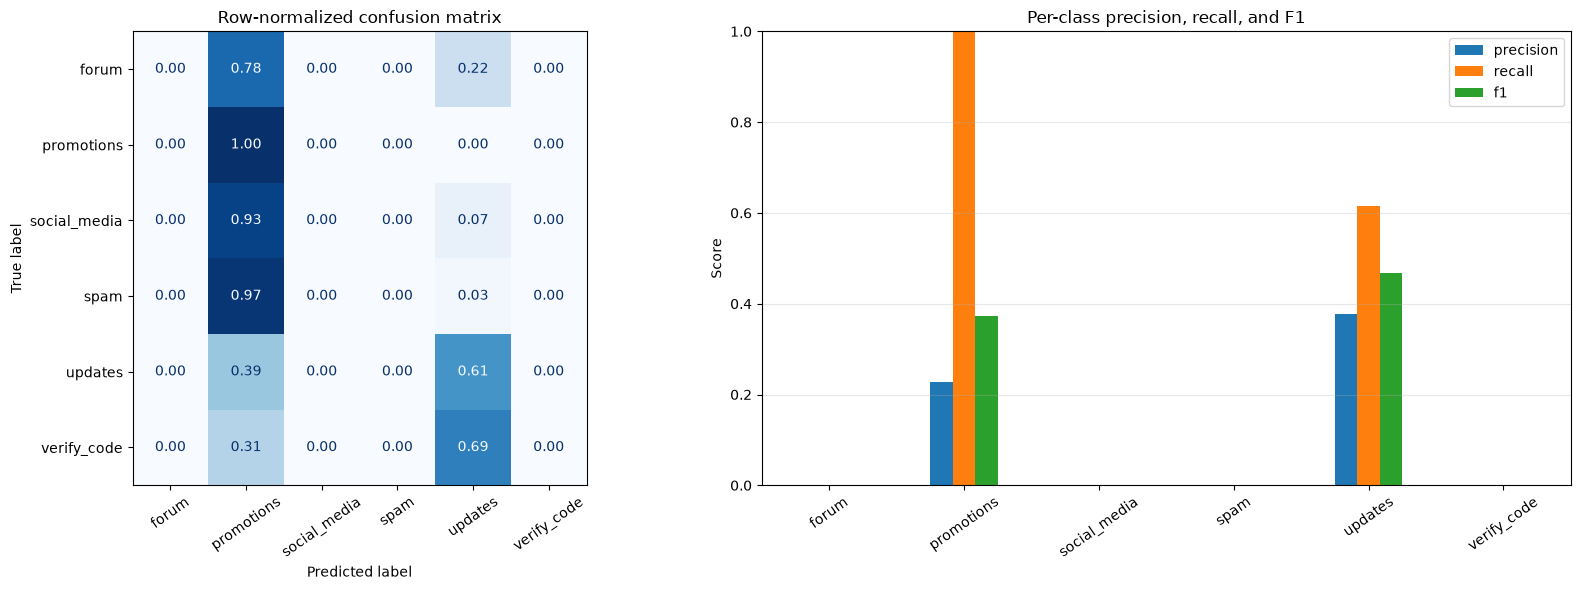

,precision,recall,f1
forum,0.000000,0.000000,0.000000
promotions,0.228383,1.000000,0.371843
social_media,0.000000,0.000000,0.000000
spam,0.000000,0.000000,0.000000
updates,0.377565,0.614699,0.467797
verify_code,0.000000,0.000000,0.000000


In [10]:
if "successful" not in globals() or successful.empty:
    print("Run inference and the metrics cell before diagnostics.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(17, 6))
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, labels=LABELS, normalize="true", values_format=".2f",
        cmap="Blues", ax=axes[0], colorbar=False,
    )
    axes[0].set_title("Row-normalized confusion matrix")
    axes[0].tick_params(axis="x", rotation=35)

    precision, recall, class_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=LABELS, zero_division=0
    )
    per_class = pd.DataFrame({
        "precision": precision, "recall": recall, "f1": class_f1,
    }, index=LABELS)
    per_class.plot.bar(ax=axes[1], ylim=(0, 1), rot=35)
    axes[1].set_title("Per-class precision, recall, and F1")
    axes[1].set_ylabel("Score")
    axes[1].grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()
    display(per_class)

## Confidence and calibration

CLM's `confidence` is the top probability minus the mean of the remaining probabilities. The table compares average confidence with empirical accuracy by bin; large gaps indicate that confidence should not be interpreted as calibrated probability.

,examples,mean_confidence,empirical_accuracy,calibration_gap
confidence_bin,,,,
"(0.4, 0.5]",71,0.451340,0.197183,0.254157
"(0.5, 0.6]",85,0.547755,0.211765,0.335990
"(0.6, 0.7]",83,0.649908,0.132530,0.517378
"(0.7, 0.8]",102,0.754874,0.245098,0.509776
"(0.8, 0.9]",159,0.854402,0.163522,0.690879
"(0.9, 1.0]",2197,0.990906,0.287210,0.703696


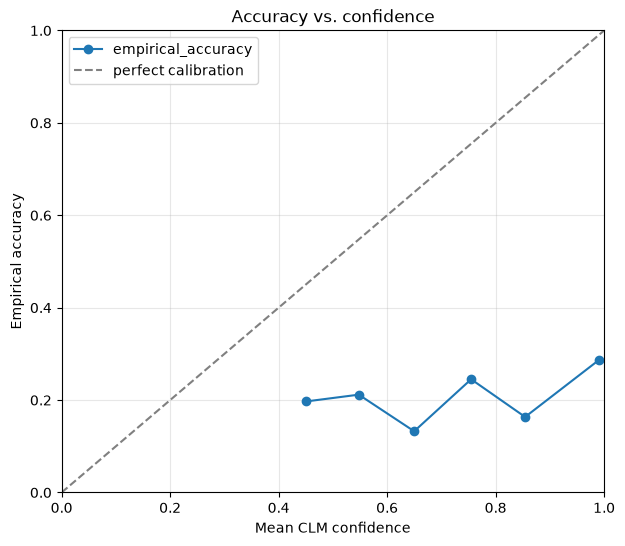

In [11]:
if "successful" not in globals() or successful.empty:
    print("Run inference and the metrics cell before calibration analysis.")
else:
    calibration_df = successful.assign(correct=lambda frame: frame["predicted_category"].eq(frame["expected_category"]))
    calibration_df["confidence_bin"] = pd.cut(
        calibration_df["confidence"], bins=np.linspace(0, 1, 11), include_lowest=True
    )
    calibration = calibration_df.groupby("confidence_bin", observed=False).agg(
        examples=("correct", "size"),
        mean_confidence=("confidence", "mean"),
        empirical_accuracy=("correct", "mean"),
    ).dropna(subset=["mean_confidence"])
    calibration["calibration_gap"] = calibration["mean_confidence"] - calibration["empirical_accuracy"]
    display(calibration)

    ax = calibration.plot(
        x="mean_confidence", y="empirical_accuracy", marker="o", legend=False, figsize=(7, 6)
    )
    ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="perfect calibration")
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean CLM confidence", ylabel="Empirical accuracy", title="Accuracy vs. confidence")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.show()

## Error analysis

Review the most confident mistakes first. Only truncated text is displayed to reduce unnecessary exposure of email content.

In [12]:
if "successful" not in globals() or successful.empty:
    print("Run inference and the metrics cell before error analysis.")
else:
    mistakes = successful.loc[
        successful["predicted_category"].ne(successful["expected_category"])
    ].merge(test_df[["id", "subject", "body"]], on="id", how="left", validate="one_to_one")
    mistakes["subject_preview"] = mistakes["subject"].astype(str).str.slice(0, 120)
    mistakes["body_preview"] = mistakes["body"].astype(str).str.replace(r"\s+", " ", regex=True).str.slice(0, 240)
    error_columns = [
        "id", "expected_category", "predicted_category", "confidence",
        "subject_preview", "body_preview",
    ]
    display(mistakes.sort_values("confidence", ascending=False)[error_columns].head(25))
    print(f"Mistakes: {len(mistakes):,}/{len(successful):,}")

,id,expected_category,predicted_category,confidence,subject_preview,body_preview
847,social_media_772,social_media,promotions,1.0,Your post is featured on #FoodChallenge,"Your group ""Tech Enthusiasts"" is live streaming. Join: social.com/live/conference."
763,social_media_31,social_media,promotions,1.0,3D World Building Challenge: $10K Prize Pool,Create immersive environment using our AR toolkit. Submit: socialcreators.io/challenge/3d-world Info pack attached.
650,social_media_187,social_media,promotions,1.0,Video Project Pitch: Educational Series,@ScienceEduChannel wants collaboration: social.com/collabs/request-5566. Concept: Monthly explainer videos. Estimate...
595,social_media_1658,social_media,promotions,1.0,Your post is featured on #FoodChallenge,"8 friends checked in at ""Downtown Cafe"". See photos and menu: social.com/places/cafe."
676,social_media_197,social_media,promotions,1.0,Live Now: Cooking Masterclass,Chef Ramirez streaming. Join: social.com/live/cooking-class.
855,social_media_81,social_media,promotions,1.0,Invitation: Collaborative Neuro-Art Installation at Venice Biennale,"Innovative Creators, The Neuroaesthetics Collective invites you to participate in ""Conscious Canvas"" - a groundbreak..."
95,forum_140,forum,promotions,1.0,Section Moderator Needed,"Apply for ""Web Development"": forum.com/mods/apply-dev-section."
418,forum_87,forum,promotions,1.0,"Achievement: 1,000 Posts Milestone","Earned ""Prolific Contributor"" title. View profile: forum.com/users/yourprofile/achievements."
738,social_media_2219,social_media,promotions,1.0,Your post is featured on #FoodChallenge,"""So inspiring!"" View: social.com/events/event456 Reply or disable: platform.com/notifications."
462,social_media_104,social_media,promotions,1.0,Trending hashtag in your field,#Sustainability trending with 12K posts. Contribute: social.com/hashtags/sustainability.


Mistakes: 1,972/2,697


## Reproducibility metadata

Record the exact dataset, model, taxonomy, temperature, sample configuration, and package versions next to the checkpoint.

In [13]:
metadata = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "dataset": DATASET_ID,
    "dataset_file": TEST_FILE,
    "test_rows": len(test_df),
    "evaluation_rows": len(evaluation_df),
    "random_state": RANDOM_STATE,
    "temperature": TEMPERATURE,
    "labels": LABELS,
    "criteria": CATEGORY_CRITERIA,
    "clm_base_url": CLM_BASE_URL,
    "clm_model": CLM_MODEL,
    "python": sys.version,
    "platform": platform.platform(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
}
metadata_path = ARTIFACT_DIR / "clm_email_evaluation_metadata.json"
metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print(f"Saved metadata: {metadata_path}")
display(pd.Series(metadata).drop(labels=["criteria"]).to_frame("value"))

Saved metadata: H:\masterswork\gitrash\CLM\CLMClient\notebooks\artifacts\clm_email_evaluation_metadata.json


,value
created_at_utc,2026-10-07T09:06:17.565072+00:00
dataset,jason23322/high-accuracy-email-classifier
dataset_file,test.json
test_rows,2697
evaluation_rows,2697
random_state,42
temperature,0.1
labels,"[forum, promotions, social_media, spam, updates, verify_code]"
clm_base_url,http://127.0.0.1:8700
clm_model,clm-latest


## Conclusions and next steps

After running the evaluation, document:

1. **Measured quality:** accuracy, macro F1, top-2 accuracy, log loss, and coverage.
2. **Weak classes:** lowest recall/F1 and the dominant confusion pairs.
3. **Confidence behavior:** whether high-confidence predictions are reliably correct.
4. **Error themes:** recurring semantic ambiguity, short messages, promotional spam overlap, or taxonomy mismatch.
5. **Next experiment:** revise criteria, compare temperatures/models, then rerun with a new checkpoint filename. Avoid tuning repeatedly on the test set; use the training split for prompt/criteria development and reserve this test split for final reporting.

# Follow-up proposal

## Baseline diagnosis

The complete 2,697-row published test split completed with 100% request coverage but poor classification quality:

- Accuracy: **26.88%** (725/2,697), with an approximate 95% Wilson interval of **25.24% to 28.59%**
- Macro F1: **13.99%**
- Top-2 accuracy: **42.23%**
- Mean confidence: **93.53%**
- Multiclass log loss: **19.37**
- Median request latency: **46.6 ms**
- Predictions collapsed to `promotions` (1,966) and `updates` (731); the other four labels were never selected.

The full holdout confirms that the 120-row pilot was directionally reliable: this is a stable model/formulation failure rather than small-sample noise. Low temperature explains the extreme confidence and log loss, but it does not change candidate ordering and therefore does not explain the top-1 label collapse.

## Prioritized experiment roadmap

The published test split has now been measured and must be treated as held out from further iteration. Build one fixed, stratified development split from the published training data, run all experiments below on that development split, freeze the selected configuration, and run the full test split only once more for final confirmation.

Run development experiments in this order, changing one factor at a time:

1. **Probability-temperature baseline** — rerun `clm-latest` at temperature `1.0`. Top-1 predictions should be unchanged, but confidence and log loss should become less extreme. This verifies that temperature is a calibration control rather than an accuracy fix.
2. **Balanced candidate wording** — replace broad definitions with short, parallel, mutually exclusive statements. This tests whether candidate-description geometry causes the two-class collapse.
3. **Projection-head ablation** — compare `clm-latest` with `clm-raw` using identical criteria. This identifies whether the released CLM projection head amplifies the bias.
4. **One-vs-rest formulation** — ask six separate binary questions and choose the class with the largest positive score. This removes competition inside one six-way softmax and tests whether independent scoring separates the classes better.
5. **Typed-choice fine-tuning** — train an email-specific projection head on the published training split and evaluate once on the untouched test split. This is the preferred route if zero-shot reformulations remain weak.

### Progression criteria

Advance a zero-shot configuration only if development macro F1 improves above 0.140 **and** it predicts all six classes. A useful intermediate target is development macro F1 >= 0.50 with no class recall equal to zero. Treat these as project thresholds, not claims about expected model performance. Do not select criteria, model, temperature, or formulation from repeated test-set results.

## Create the development holdout from training data

The next cell creates a fixed 80/20 stratified split from the published training split. Use `development_df` for all proposal experiments and `finetune_train_df` for supervised training. It verifies that neither partition overlaps the published test IDs.

In [14]:
TRAIN_FILE = "train.json"
DEVELOPMENT_FRACTION = 0.20

train_url = f"hf://datasets/{DATASET_ID}/{TRAIN_FILE}"
published_train_df = pd.read_json(train_url, storage_options={"token": HF_TOKEN})

if set(published_train_df["id"]).intersection(test_df["id"]):
    raise ValueError("Published train and test IDs overlap")
if set(published_train_df["category"].unique()) != set(LABELS):
    raise ValueError("Published training labels do not match the evaluation taxonomy")

finetune_train_df, development_df = train_test_split(
    published_train_df,
    test_size=DEVELOPMENT_FRACTION,
    stratify=published_train_df["category"],
    random_state=RANDOM_STATE,
)
finetune_train_df = finetune_train_df.sort_values("id").reset_index(drop=True)
development_df = development_df.sort_values("id").reset_index(drop=True)

assert set(finetune_train_df["id"]).isdisjoint(development_df["id"])
assert set(development_df["id"]).isdisjoint(test_df["id"])

print(f"Fine-tuning partition: {len(finetune_train_df):,} rows")
print(f"Development partition: {len(development_df):,} rows")
print(f"Published test holdout: {len(test_df):,} rows (not used for iteration)")
display(development_df["category"].value_counts().reindex(LABELS).rename("count").to_frame())

Fine-tuning partition: 8,624 rows
Development partition: 2,156 rows
Published test holdout: 2,697 rows (not used for iteration)


,count
category,
forum,360
promotions,359
social_media,359
spam,359
updates,359
verify_code,360


In [15]:
FOLLOW_UP_EXPERIMENTS = pd.DataFrame([
    {
        "order": 0,
        "experiment_id": "baseline_latest_t01",
        "model": "clm-latest",
        "temperature": 0.1,
        "formulation": "six-way-v1",
        "purpose": "Recorded baseline",
        "evaluation_split": "published-test-full",
        "status": "complete",
    },
    {
        "order": 1,
        "experiment_id": "baseline_latest_t10",
        "model": "clm-latest",
        "temperature": 1.0,
        "formulation": "six-way-v1",
        "purpose": "Measure temperature effect on probabilities and calibration",
        "evaluation_split": "published-test-full",
        "status": "complete",
    },
    {
        "order": 2,
        "experiment_id": "criteria_v2_latest_t10",
        "model": "clm-latest",
        "temperature": 1.0,
        "formulation": "six-way-v2",
        "purpose": "Test short parallel class prototypes",
        "evaluation_split": "train-derived-development",
        "status": "planned",
    },
    {
        "order": 3,
        "experiment_id": "criteria_v2_raw_t10",
        "model": "clm-raw",
        "temperature": 1.0,
        "formulation": "six-way-v2",
        "purpose": "Ablate the released projection head",
        "evaluation_split": "train-derived-development",
        "status": "planned",
    },
    {
        "order": 4,
        "experiment_id": "one_vs_rest_latest_t10",
        "model": "clm-latest",
        "temperature": 1.0,
        "formulation": "six-binary-questions",
        "purpose": "Test independent class scoring",
        "evaluation_split": "train-derived-development",
        "status": "planned",
    },
    {
        "order": 5,
        "experiment_id": "email_choice_finetuned",
        "model": "email-choice-head",
        "temperature": 1.0,
        "formulation": "six-way-v2",
        "purpose": "Learn dataset-specific boundaries from the training split",
        "evaluation_split": "published-test-final-once",
        "status": "complete",
    },
]).set_index("order")

display(FOLLOW_UP_EXPERIMENTS)

,experiment_id,model,temperature,formulation,purpose,evaluation_split,status
order,,,,,,,
0,baseline_latest_t01,clm-latest,0.1,six-way-v1,Recorded baseline,published-test-full,complete
1,baseline_latest_t10,clm-latest,1.0,six-way-v1,Measure temperature effect on probabilities and calibration,published-test-full,complete
2,criteria_v2_latest_t10,clm-latest,1.0,six-way-v2,Test short parallel class prototypes,train-derived-development,planned
3,criteria_v2_raw_t10,clm-raw,1.0,six-way-v2,Ablate the released projection head,train-derived-development,planned
4,one_vs_rest_latest_t10,clm-latest,1.0,six-binary-questions,Test independent class scoring,train-derived-development,planned
5,email_choice_finetuned,email-choice-head,1.0,six-way-v2,Learn dataset-specific boundaries from the training split,published-test-final-once,complete


## Experiment protocol and checkpoint hygiene

The batch cell resumes by email ID. Reusing the original checkpoint after changing criteria, model, temperature, or formulation would silently reuse stale predictions. Every experiment therefore needs a unique checkpoint and metadata file.

For each experiment:

1. Select one row from `FOLLOW_UP_EXPERIMENTS`.
2. Apply only that row's intended change on the fixed train-derived development split.
3. Assign a unique checkpoint with the helper below.
4. Run the smoke test and confirm six probability keys summing to 1.
5. Run the same fixed development IDs for every zero-shot experiment.
6. Record accuracy, macro F1, top-2 accuracy, log loss, predicted-class counts, minimum class recall, and calibration gap.
7. Do not alter the development sample between experiments.

Do not use the published test labels, errors, or metrics to choose among planned configurations. The complete 2,697-row test baseline is now recorded; reserve the next complete test evaluation for the single frozen final configuration.

In [16]:
CATEGORY_CRITERIA_V2 = {
    "forum": "This email is primarily a notification about a forum post, discussion thread, or community reply.",
    "promotions": "This email is primarily a legitimate advertisement, discount, sale, or marketing offer.",
    "social_media": "This email is primarily a notification about activity on a social-media account or network.",
    "spam": "This email is primarily unsolicited, deceptive, suspicious, scam-like, or irrelevant bulk content.",
    "updates": "This email is primarily a non-promotional status update about an account, product, service, order, bill, or trip.",
    "verify_code": "This email is primarily delivering a one-time password, login code, or account-verification code.",
}

def configure_follow_up(experiment_id: str) -> dict:
    matches = FOLLOW_UP_EXPERIMENTS.loc[
        FOLLOW_UP_EXPERIMENTS["experiment_id"].eq(experiment_id)
    ]
    if len(matches) != 1:
        raise ValueError(f"Unknown or duplicate experiment_id: {experiment_id!r}")
    experiment = matches.iloc[0].to_dict()
    experiment["checkpoint_path"] = ARTIFACT_DIR / f"clm_email_predictions_{experiment_id}.csv"
    experiment["metadata_path"] = ARTIFACT_DIR / f"clm_email_metadata_{experiment_id}.json"
    return experiment

NEXT_EXPERIMENT = configure_follow_up("baseline_latest_t10")
display(pd.Series(NEXT_EXPERIMENT, name="next_experiment").to_frame())

print("Before batch inference, explicitly assign:")
print(f"CLM_MODEL = {NEXT_EXPERIMENT['model']!r}")
print(f"TEMPERATURE = {NEXT_EXPERIMENT['temperature']}")
print(f"CHECKPOINT_PATH = Path({str(NEXT_EXPERIMENT['checkpoint_path'])!r})")

,next_experiment
experiment_id,baseline_latest_t10
model,clm-latest
temperature,1.0
formulation,six-way-v1
purpose,Measure temperature effect on probabilities and calibration
evaluation_split,published-test-full
status,complete
checkpoint_path,H:\masterswork\gitrash\CLM\CLMClient\notebooks\artifacts\clm_email_predictions_baseline_latest_t10.csv
metadata_path,H:\masterswork\gitrash\CLM\CLMClient\notebooks\artifacts\clm_email_metadata_baseline_latest_t10.json


Before batch inference, explicitly assign:
CLM_MODEL = 'clm-latest'
TEMPERATURE = 1.0
CHECKPOINT_PATH = Path('H:\\masterswork\\gitrash\\CLM\\CLMClient\\notebooks\\artifacts\\clm_email_predictions_baseline_latest_t10.csv')


## Typed-choice fine-tuning proposal

If the controlled zero-shot experiments still collapse, prepare the Hugging Face **training split** in the typed-decision schema consumed by `train/finetune.py` and `train/adapters.py`:

- `id`: stable email ID
- `state`: `{subject, body}`
- `questions`: `{"category": {"type": "choice", "instructions": ..., "criteria": CATEGORY_CRITERIA_V2}}`
- `gold`: `{"category": {"label": <category>}}`
- `workflow`: `all`

Store local Parquet files as `<data-root>/all/train*.parquet` and `<data-root>/all/test*.parquet`; that is the directory layout required by the current `load_typed_rows` implementation. During iterative training experiments, populate the trainer's required `test*.parquet` input from a fixed train-derived development partition, not the published test split. After all choices are frozen, run one final training/evaluation workflow with the published test split for reporting.

Run training in Linux/WSL with the GPU dependencies—not in the native-Windows client environment. Start with a frozen Qwen3-8B encoder, the released head as `--init-ckpt`, hard targets, and `softce` because this experiment has one closed six-option decision per email:

```bash
python train/finetune.py \
  --task choice \
  --data <email-typed-parquet-root> \
  --workflow all \
  --targets hard \
  --loss softce \
  --init-ckpt <released-head.pt> \
  --embed-url http://127.0.0.1:8090/v1/embeddings \
  --served-model-name qwen3-8b \
  --out-dir runs/email-choice-v1
```

Establish the unmodified trainer baseline first. Select epochs using validation accuracy, report the held-out test result once, and preserve the baseline checkpoint and command for comparison.

## Follow-up decision log

Record each completed experiment here before starting the next:

| Experiment | Accuracy | Macro F1 | Top-2 | Log loss | Predicted classes | Min recall | Decision |
|---|---:|---:|---:|---:|---:|---:|---|
| `baseline_latest_t01` | 0.2688 | 0.1399 | 0.4223 | 19.3741 | 2/6 | 0.0000 | Full test baseline; reject due to class collapse and severe overconfidence |
| `baseline_latest_t10` | 0.2688 | 0.1399 | 0.4223 | 3.2873 | 2/6 | 0.0000 | Temperature fixed for fair probability comparison; class collapse unchanged |
| `criteria_v2_latest_t10` |  |  |  |  |  |  | Pending |
| `criteria_v2_raw_t10` |  |  |  |  |  |  | Pending |
| `one_vs_rest_latest_t10` |  |  |  |  |  |  | Pending |
| `email_choice_finetuned` | 0.9759 | 0.9759 | 0.9967 | 0.0707 | 6/6 | 0.9556 | Accept; large paired improvement with stable seed results |

# Supervised CLM fine-tuning experiment

## Objective and experimental contract

The zero-shot result establishes that the CLM client and real server work, but the reference projection head does not separate this email taxonomy. This experiment asks whether a **task-specific CLM projection head** can become a useful classifier while the Qwen3-8B encoder remains frozen.

To make the pre/post result attributable to fine-tuning:

- The six labels, state representation, question instructions, candidate descriptions, and published test rows are identical before and after training.
- Both standardized test runs use temperature `1.0`; temperature `0.1` is retained only as the original diagnostic run.
- The published training split is divided deterministically into fit and development partitions.
- Hyperparameters and epoch selection use training/internal-validation/development data only.
- Seed 42 is declared as the final checkpoint before reading published-test performance. Seeds 123 and 2026 measure development variance and are not used to cherry-pick the test result.
- The complete published test split is evaluated once with the frozen seed-42 checkpoint, paired row-for-row with the zero-shot baseline.

## Leakage-safe data contract and provenance

The trainer consumes typed-decision Parquet rows. Each row contains a stable email ID, JSON-encoded `{subject, body}` state, the same six-way question, and one gold category. File and ID hashes make the experiment reproducible and detect accidental data changes.

In [17]:
import hashlib

TYPED_DATA_ROOT = ARTIFACT_DIR / "email_typed_choice"
TYPED_MANIFEST_PATH = TYPED_DATA_ROOT / "manifest.json"
typed_manifest = json.loads(TYPED_MANIFEST_PATH.read_text(encoding="utf-8"))

def file_sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()

typed_train_path = Path(typed_manifest["partitions"]["fit"]["file"])
typed_development_path = Path(typed_manifest["partitions"]["development"]["file"])
if file_sha256(typed_train_path) != typed_manifest["partitions"]["fit"]["file_sha256"]:
    raise ValueError("Fine-tuning Parquet hash does not match its manifest")
if file_sha256(typed_development_path) != typed_manifest["partitions"]["development"]["file_sha256"]:
    raise ValueError("Development Parquet hash does not match its manifest")
if any(typed_manifest["overlap_counts"].values()):
    raise ValueError(f"Partition overlap detected: {typed_manifest['overlap_counts']}")

partition_table = pd.DataFrame({
    name: {
        "rows": details["rows"],
        "ids_sha256": details["ids_sha256"],
    }
    for name, details in typed_manifest["partitions"].items()
}).T
display(partition_table)
print(f"Fit Parquet SHA-256: {typed_manifest['partitions']['fit']['file_sha256']}")
print(f"Development Parquet SHA-256: {typed_manifest['partitions']['development']['file_sha256']}")
print(f"Overlap counts: {typed_manifest['overlap_counts']}")

,rows,ids_sha256
fit,8624,d14dba0991065bd94d71fb5c42f8fe35074d5faf1f6418713edbb7c8927af20e
development,2156,2a3717c3b5efb082491764763676690ac9ad718b293063881d50f29cd4b4c0ea
published_test,2697,443184fab521027c8829d8fd516e4490dabc0072ff1c8dccfeec97f14c05074c


Fit Parquet SHA-256: dbe0df524af729569a528255d71e3b3965e0bd58a042b81440dafe1f18018f9c
Development Parquet SHA-256: 91b40c5fe5b9cdfb9aa19a71b826d742c3ed2393f0a84244cabc5eeb1f607f6a
Overlap counts: {'fit_dev': 0, 'train_test': 0, 'dev_test': 0}


In [18]:
REBUILD_FINE_TUNING_DATA = False

def to_typed_decisions(frame: pd.DataFrame) -> pd.DataFrame:
    wire_question = {
        "category": {
            "type": "choice",
            "instructions": CATEGORY_QUESTION.instructions,
            "criteria": CATEGORY_CRITERIA,
        }
    }
    return pd.DataFrame({
        "id": frame["id"].astype(str),
        "state": [
            json.dumps({"subject": str(subject).strip(), "body": str(body).strip()}, ensure_ascii=False, sort_keys=True)
            for subject, body in zip(frame["subject"], frame["body"])
        ],
        "questions": json.dumps(wire_question, ensure_ascii=False, sort_keys=True),
        "gold": [json.dumps({"category": {"label": str(label)}}, sort_keys=True) for label in frame["category"]],
        "workflow": "all",
    })

if REBUILD_FINE_TUNING_DATA:
    workflow_dir = TYPED_DATA_ROOT / "all"
    workflow_dir.mkdir(parents=True, exist_ok=True)
    to_typed_decisions(finetune_train_df).to_parquet(workflow_dir / "train.parquet", index=False)
    to_typed_decisions(development_df).to_parquet(workflow_dir / "test.parquet", index=False)
    print("Rebuilt typed-decision Parquet files. Regenerate the manifest hashes before training.")
else:
    print("Using the hash-verified typed-decision artifacts recorded above.")

display(pd.read_parquet(typed_train_path).head(2))

Using the hash-verified typed-decision artifacts recorded above.


,id,state,questions,gold,workflow
0,forum_10,"{""body"": ""Thread \""Network issues\"" moved from General to correct section. Continue: forum.com/threads/net-issues."",...","{""category"": {""criteria"": {""forum"": ""Community forum conversations, discussion threads, group posts, replies, or mem...","{""category"": {""label"": ""forum""}}",all
1,forum_1000,"{""body"": ""Thread: \""Discussion 870\"" started by DataWiz. Settings: forum.com/thread/123."", ""subject"": ""Mod applicati...","{""category"": {""criteria"": {""forum"": ""Community forum conversations, discussion threads, group posts, replies, or mem...","{""category"": {""label"": ""forum""}}",all


## Training design and overfitting controls

- **Frozen encoder:** Qwen3-8B embeddings are computed once; only the small state/action projection heads and logit scale are optimized.
- **Warm start:** initialize from the released `CLM_v0.1-8B.pt` head rather than random weights.
- **Objective:** hard-label six-way soft cross-entropy (`softce`) matches the deployed closed-set decision.
- **Regularization:** weight decay `1e-4`, fixed batch size 256, and no encoder updates reduce capacity and variance.
- **Epoch selection:** the trainer reserves 10% of fit IDs as an internal validation set and saves the highest-validation-accuracy checkpoint.
- **Early stopping:** stop after five epochs without validation-accuracy improvement; the maximum is 30 epochs.
- **Variance check:** repeat identical training for seeds 42, 123, and 2026. The predeclared seed-42 model is the final test model.
- **Bias checks:** report every class independently; balanced aggregate accuracy alone is insufficient.

In [19]:
RUN_FINE_TUNING = False
WSL_DATA_ROOT = "/mnt/h/masterswork/gitrash/CLM/CLMClient/notebooks/artifacts/email_typed_choice"
WSL_RUN_ROOT = "/mnt/h/masterswork/gitrash/CLM/CLMClient/notebooks/artifacts/email_choice_finetune_v1"
WSL_REFERENCE_HEAD = "/root/.cache/clm/CLM_v0.1-8B.pt"

training_command = (
    "cd /mnt/h/masterswork/gitrash/CLM && "
    "/opt/clm-venv/bin/python train/finetune.py "
    "--task choice "
    f"--data {WSL_DATA_ROOT} --workflow all "
    "--targets hard --loss softce "
    f"--init-ckpt {WSL_REFERENCE_HEAD} "
    "--embed-url http://127.0.0.1:8090/v1/embeddings --served-model-name qwen3-8b --max-len 2048 "
    "--epochs 30 --batch 256 --lr 5e-4 --weight-decay 1e-4 --val-frac 0.1 --patience 5 --seed 42 --gpu 0 "
    f"--out-dir {WSL_RUN_ROOT}"
)
print("Reproducible WSL training command:\n")
print(f"wsl.exe -d Ubuntu-24.04 -- bash -lc {training_command!r}")

if RUN_FINE_TUNING:
    import subprocess
    subprocess.run(["wsl.exe", "-d", "Ubuntu-24.04", "--", "bash", "-lc", training_command], check=True)
else:
    print("Training is gated because completed, traceable checkpoints already exist.")

Reproducible WSL training command:

wsl.exe -d Ubuntu-24.04 -- bash -lc 'cd /mnt/h/masterswork/gitrash/CLM && /opt/clm-venv/bin/python train/finetune.py --task choice --data /mnt/h/masterswork/gitrash/CLM/CLMClient/notebooks/artifacts/email_typed_choice --workflow all --targets hard --loss softce --init-ckpt /root/.cache/clm/CLM_v0.1-8B.pt --embed-url http://127.0.0.1:8090/v1/embeddings --served-model-name qwen3-8b --max-len 2048 --epochs 30 --batch 256 --lr 5e-4 --weight-decay 1e-4 --val-frac 0.1 --patience 5 --seed 42 --gpu 0 --out-dir /mnt/h/masterswork/gitrash/CLM/CLMClient/notebooks/artifacts/email_choice_finetune_v1'
Training is gated because completed, traceable checkpoints already exist.


## Training dynamics, seed stability, and generalization

The plots below distinguish optimization progress from generalization. Falling training loss with worsening validation loss would indicate overfitting; seed-to-seed spread estimates optimization/split variance.

,best_epoch,internal_validation_accuracy,development_accuracy,development_log_loss,minutes
seed,,,,,
42,12,0.989559,0.982839,0.046392,3.38
123,10,0.987239,0.981447,0.046838,0.24
2026,15,0.989559,0.988404,0.034271,0.29


Development accuracy mean: 98.4230%
Development accuracy sample SD: 0.3681%


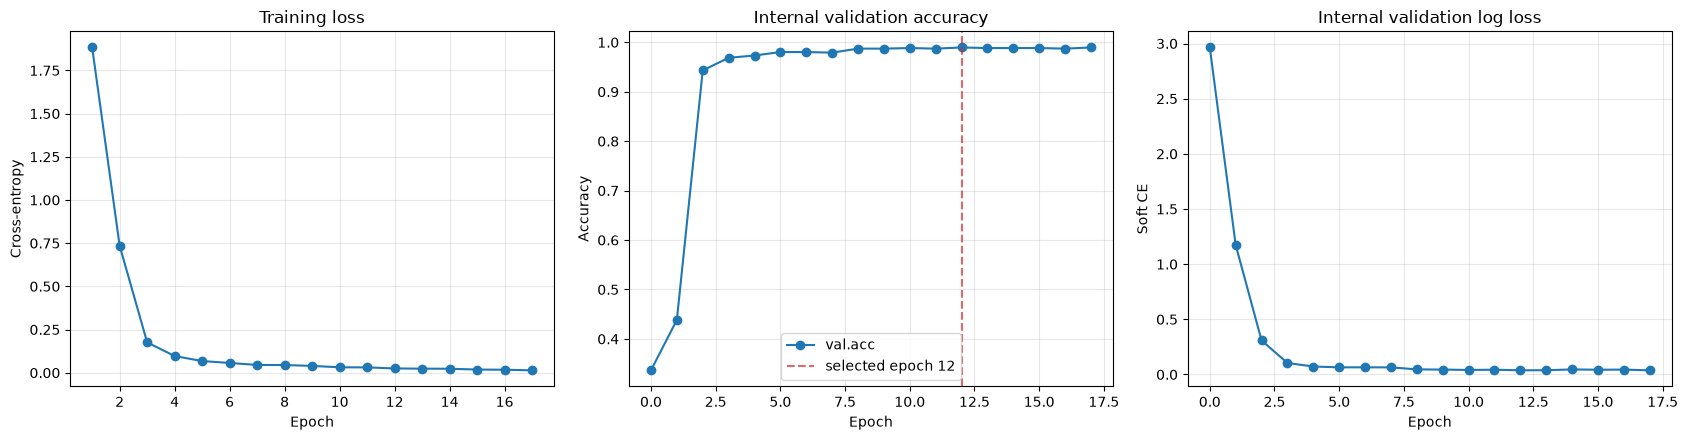

In [20]:
fine_tune_runs = {
    42: ARTIFACT_DIR / "email_choice_finetune_v1",
    123: ARTIFACT_DIR / "email_choice_finetune_seed123",
    2026: ARTIFACT_DIR / "email_choice_finetune_seed2026",
}
seed_records = []
for seed, run_dir in fine_tune_runs.items():
    summary = json.loads((run_dir / "finetune_summary.json").read_text(encoding="utf-8"))
    seed_records.append({
        "seed": seed,
        "best_epoch": summary["best_epoch"],
        "internal_validation_accuracy": summary["val_acc"],
        "development_accuracy": summary["test"]["acc"],
        "development_log_loss": summary["test"]["soft_ce"],
        "minutes": summary["minutes"],
    })
seed_results = pd.DataFrame(seed_records).set_index("seed")
display(seed_results)
print(f"Development accuracy mean: {seed_results['development_accuracy'].mean():.4%}")
print(f"Development accuracy sample SD: {seed_results['development_accuracy'].std(ddof=1):.4%}")

history = pd.json_normalize(json.loads((fine_tune_runs[42] / "history.json").read_text(encoding="utf-8")))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
history.dropna(subset=["train_loss"]).plot(x="epoch", y="train_loss", marker="o", ax=axes[0], legend=False)
history.plot(x="epoch", y="val.acc", marker="o", ax=axes[1], legend=False)
history.plot(x="epoch", y="val.soft_ce", marker="o", ax=axes[2], legend=False)
axes[0].set_title("Training loss"); axes[0].set_ylabel("Cross-entropy")
axes[1].set_title("Internal validation accuracy"); axes[1].set_ylabel("Accuracy")
axes[2].set_title("Internal validation log loss"); axes[2].set_ylabel("Soft CE")
for axis in axes:
    axis.grid(alpha=0.3)
    axis.set_xlabel("Epoch")
axes[1].axvline(12, color="tab:red", linestyle="--", alpha=0.7, label="selected epoch 12")
axes[1].legend()
plt.tight_layout()
plt.show()

## Deployment and standardized final evaluation

The tuned checkpoint is served as `email-choice-v1` on port 8701 while the reference `clm-latest` model remains on port 8700. This avoids overwriting the baseline. Both final prediction files use the same 2,697 IDs, question contract, and temperature `1.0`.

The fine-tuned API was started with:

```powershell
wsl.exe -d Ubuntu-24.04 -- bash -lc 'cd /mnt/h/masterswork/gitrash/CLM && /opt/clm-venv/bin/clm-serve --emb-url http://127.0.0.1:8090/v1/embeddings --port 8701 --max-tokens 2048 --ckpt /root/.cache/clm/CLM_v0.1-8B.pt --model email-choice-v1=/mnt/h/masterswork/gitrash/CLM/CLMClient/notebooks/artifacts/email_choice_finetune_v1/best_head.pt'
```

Prediction CSVs are resumable and immutable inputs to the comparison below. The warm-cache latency microbenchmark is reported separately because the first full fine-tuned pass populated a new projection cache while the zero-shot server was already warm.

In [21]:
pre_metrics = json.loads((ARTIFACT_DIR / "clm_email_metrics_zero_shot_t1.json").read_text(encoding="utf-8"))
post_metrics = json.loads((ARTIFACT_DIR / "clm_email_metrics_finetuned_v1_t1.json").read_text(encoding="utf-8"))
warm_latency = json.loads((ARTIFACT_DIR / "clm_email_warm_latency.json").read_text(encoding="utf-8"))

metric_names = ["accuracy", "macro_f1", "weighted_f1", "top2_accuracy", "log_loss", "mean_confidence"]
pre_post_metrics = pd.DataFrame({
    "zero_shot": {name: pre_metrics[name] for name in metric_names},
    "fine_tuned": {name: post_metrics[name] for name in metric_names},
})
pre_post_metrics["absolute_change"] = pre_post_metrics["fine_tuned"] - pre_post_metrics["zero_shot"]
display(pre_post_metrics)

latency_table = pd.DataFrame(warm_latency).T
latency_table.index.name = "model"
display(latency_table)
print("Latency is a warm-cache microbenchmark over the same 200 emails; it is not a cold-start measurement.")

,zero_shot,fine_tuned,absolute_change
accuracy,0.268817,0.975899,0.707082
macro_f1,0.139940,0.975930,0.835990
weighted_f1,0.139784,0.975928,0.836144
top2_accuracy,0.422321,0.996663,0.574342
log_loss,3.287347,0.070694,-3.216652
mean_confidence,0.531271,0.974342,0.443071


,n,median_ms,p90_ms,mean_ms
model,,,,
zero_shot,200.0,1.5,1.8,1.5855
finetuned,200.0,3.2,3.9,3.3295


Latency is a warm-cache microbenchmark over the same 200 emails; it is not a cold-start measurement.


In [22]:
comparison = json.loads((ARTIFACT_DIR / "clm_email_pre_post_comparison.json").read_text(encoding="utf-8"))
comparison_summary = pd.Series({
    "paired_test_rows": comparison["paired_rows"],
    "zero_shot_accuracy": comparison["accuracy_pre"],
    "fine_tuned_accuracy": comparison["accuracy_post"],
    "accuracy_gain": comparison["accuracy_delta"],
    "accuracy_gain_ci_low": comparison["accuracy_delta_bootstrap_95_ci"][0],
    "accuracy_gain_ci_high": comparison["accuracy_delta_bootstrap_95_ci"][1],
    "baseline_wrong_tuned_correct": comparison["mcnemar_baseline_wrong_tuned_correct"],
    "baseline_correct_tuned_wrong": comparison["mcnemar_baseline_correct_tuned_wrong"],
    "mcnemar_exact_pvalue": comparison["mcnemar_exact_pvalue"],
    "zero_shot_ece_10": comparison["calibration_pre"]["ece_10"],
    "fine_tuned_ece_10": comparison["calibration_post"]["ece_10"],
    "zero_shot_brier": comparison["calibration_pre"]["multiclass_brier"],
    "fine_tuned_brier": comparison["calibration_post"]["multiclass_brier"],
})
display(comparison_summary.to_frame("value"))

fine_tuned_per_class = pd.DataFrame(comparison["per_class_post"]).T
display(fine_tuned_per_class)

,value
paired_test_rows,2697.000000
zero_shot_accuracy,0.268817
fine_tuned_accuracy,0.975899
accuracy_gain,0.707082
accuracy_gain_ci_low,0.697812
accuracy_gain_ci_high,0.715981
baseline_wrong_tuned_correct,1915.000000
baseline_correct_tuned_wrong,8.000000
mcnemar_exact_pvalue,0.000000
zero_shot_ece_10,0.340645


,precision,recall,f1-score,support
forum,0.986239,0.955556,0.970655,450.0
promotions,0.997743,0.984410,0.991031,449.0
social_media,0.948827,0.991091,0.969499,449.0
spam,0.965066,0.984410,0.974642,449.0
updates,0.969163,0.979955,0.974529,449.0
verify_code,0.990847,0.960089,0.975225,451.0


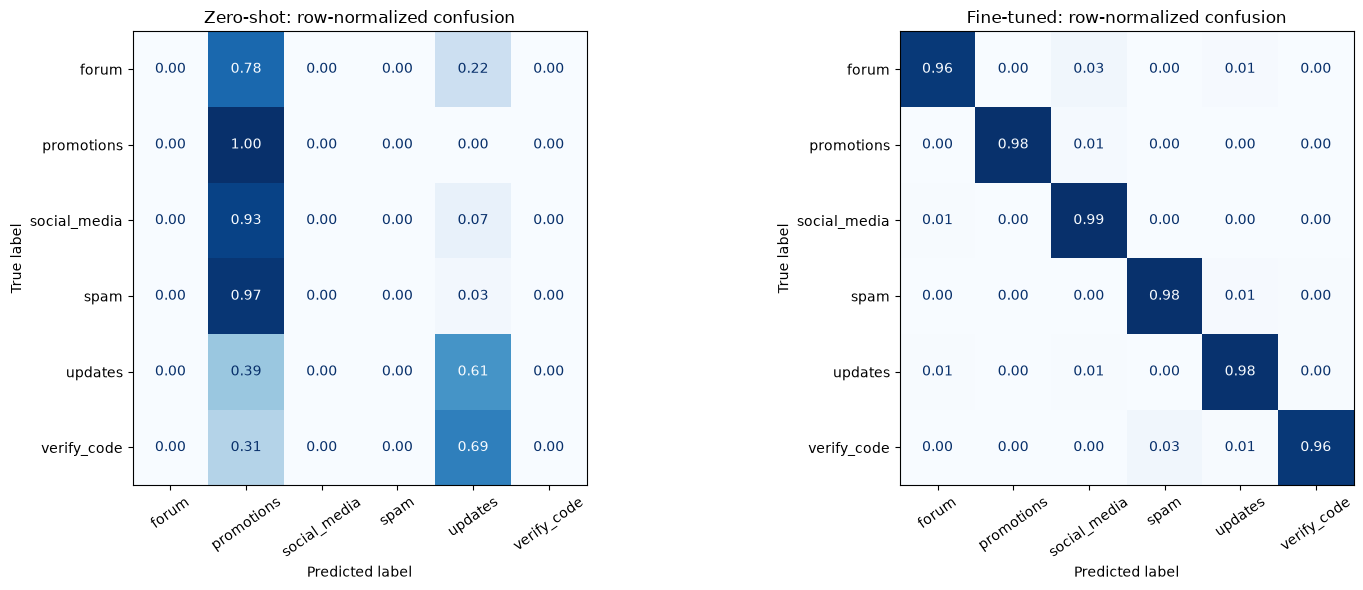

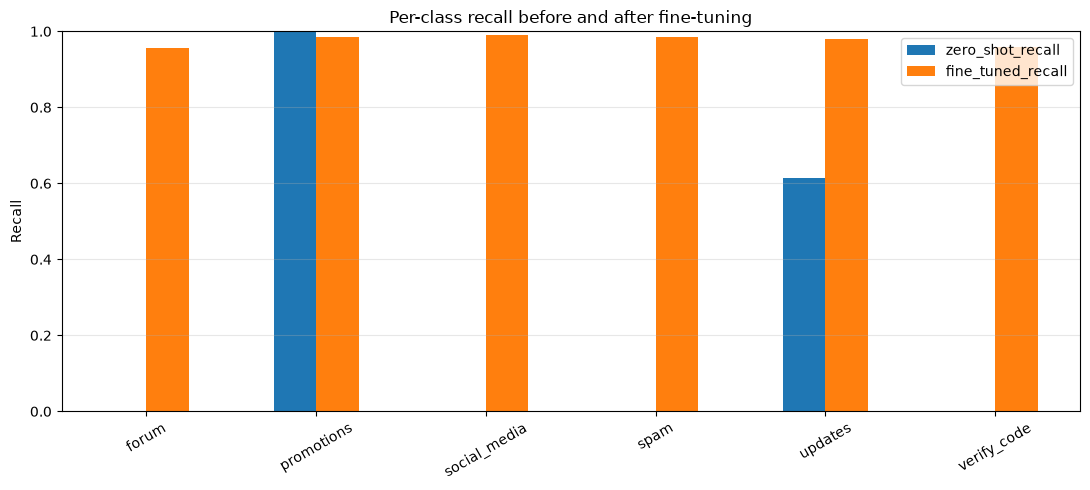

In [23]:
pre_predictions = pd.read_csv(ARTIFACT_DIR / "clm_email_predictions_zero_shot_t1.csv").sort_values("id")
post_predictions = pd.read_csv(ARTIFACT_DIR / "clm_email_predictions_finetuned_v1_t1.csv").sort_values("id")
if not pre_predictions["id"].reset_index(drop=True).equals(post_predictions["id"].reset_index(drop=True)):
    raise ValueError("Pre/post prediction IDs are not paired")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for axis, frame, title in [
    (axes[0], pre_predictions, "Zero-shot"),
    (axes[1], post_predictions, "Fine-tuned"),
]:
    ConfusionMatrixDisplay.from_predictions(
        frame["expected_category"], frame["predicted_category"], labels=LABELS,
        normalize="true", values_format=".2f", cmap="Blues", colorbar=False, ax=axis,
    )
    axis.set_title(f"{title}: row-normalized confusion")
    axis.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

per_class_plot = pd.DataFrame({
    "zero_shot_recall": [pre_metrics["classification_report"][label]["recall"] for label in LABELS],
    "fine_tuned_recall": [post_metrics["classification_report"][label]["recall"] for label in LABELS],
}, index=LABELS)
ax = per_class_plot.plot.bar(figsize=(11, 5), ylim=(0, 1), rot=30)
ax.set(title="Per-class recall before and after fine-tuning", ylabel="Recall")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Overfitting, bias, variance, and calibration assessment

- **Optimization:** seed 42 improved rapidly through epoch 5 and selected epoch 12. Later training loss continued to fall, but early stopping prevented indefinite fitting after validation accuracy plateaued.
- **Development-to-test gap:** seed-42 development accuracy was 98.28% and final published-test accuracy was 97.59%, a **0.69 percentage-point** gap. Because both partitions come from the same synthetic generator, this is not evidence of robustness to real-world distribution shift.
- **Training-seed variance:** development accuracy across seeds 42, 123, and 2026 averaged 98.42% with a sample standard deviation of **0.37 percentage points**. The outer fit/development partition was fixed; this measures sensitivity to the internal validation split, initialization, and batch order, not data-split variance.
- **Class bias:** final per-class recall ranges from 95.56% (`forum`) to 99.11% (`social_media`); no class has zero recall and all class F1 scores exceed 0.969.
- **Calibration:** 10-bin expected calibration error improved from 0.341 to 0.007, and multiclass Brier score improved from 1.002 to 0.036.
- **Paired evidence:** fine-tuning corrected 1,915 emails the baseline missed while breaking only 8 previously correct cases. The exact McNemar probability under equal paired error rates underflows standard floating-point precision; the direction is unequivocal.
- **Remaining risk:** the source dataset is synthetic and highly regular. Strong in-distribution performance does not establish robustness to real enterprise email, adversarial spam, language variation, temporal drift, or different label definitions.

In [24]:
tuned_errors = post_predictions.loc[
    post_predictions["predicted_category"].ne(post_predictions["expected_category"])
].merge(test_df[["id", "subject", "body"]], on="id", how="left", validate="one_to_one")
tuned_errors["subject_preview"] = tuned_errors["subject"].astype(str).str.slice(0, 120)
tuned_errors["body_preview"] = tuned_errors["body"].astype(str).str.replace(r"\s+", " ", regex=True).str.slice(0, 220)

confusion_pairs = tuned_errors.groupby(
    ["expected_category", "predicted_category"]
).size().sort_values(ascending=False).rename("count").to_frame()
display(confusion_pairs.head(15))
display(tuned_errors.sort_values("max_probability", ascending=False)[[
    "id", "expected_category", "predicted_category", "max_probability",
    "subject_preview", "body_preview",
]].head(25))
print(f"Fine-tuned errors: {len(tuned_errors):,}/{len(post_predictions):,}")

,,count
expected_category,predicted_category,
forum,social_media,15
verify_code,spam,15
promotions,social_media,6
forum,updates,5
spam,updates,4
social_media,forum,3
updates,social_media,3
verify_code,updates,3
updates,forum,3


,id,expected_category,predicted_category,max_probability,subject_preview,body_preview
35,spam_50,spam,updates,0.998513,Visa Application Status Update,Case V7823 requires additional documents. Upload: visa-application-update.gov/portal Document list attached.
6,forum_190,forum,updates,0.996442,Two-Factor Authentication Enforcement Notice,Required for all accounts by Dec 1: security.forum.com/2fa. Setup guides for authenticator apps and hardware keys. B...
51,verify_code_188,verify_code,updates,0.994380,Critical Patch Authorization: 789215,Emergency security patch deployment approval: Code 789215. Sign-off acknowledges potential service disruption. Chang...
10,forum_238,forum,updates,0.986684,Security Upgrade Notice,Password reset required. Instructions: forum.com/security-update-aug.
27,social_media_105,social_media,forum,0.982700,"New comment in ""Career Growth"" thread","""Consider certification programs"" - reply: social.com/comments/career882."
34,spam_241,spam,promotions,0.980141,Exclusive Luxury Yacht Charter Offer,You've been selected for our Platinum Member trial charter experience! Enjoy 3-day Mediterranean cruise for only $99...
15,forum_667,forum,social_media,0.979087,New featured guide: photography,"Trending: ""cooking"" (234 comments). View: forum.com/thread/123."
21,promotions_108,promotions,social_media,0.970919,Subscription Box Spoiler: Next Month's Theme,Beach getaway theme revealed! Customize now: subscriptionbox.com/next-box.
11,forum_246,forum,social_media,0.960888,New Content Initiative: Expert Webinar Series,"We're launching exclusive live sessions with industry pioneers: 1) August 25: Cloud security with AWS architect, 2) ..."
37,spam_65,spam,updates,0.952741,Bank Levy Authorization Notice,Court order #LEV-783. Contest: financial-levy-contest.org Account freeze pending.


Fine-tuned errors: 65/2,697


## Robustness and architecture controls

A high score on a template-generated benchmark can be inflated by repeated content. The next cell normalizes Unicode, case, and whitespace; then it measures exact subject-plus-body and body-only overlap between the fit partition and the published test. It reports tuned quality separately on overlapping and non-overlapping rows. This is stricter than the earlier ID-disjointness check, but it still does not detect paraphrases or prove real-email generalization.

The following linear-probe control trains multinomial logistic regression on the same frozen Qwen state embeddings and fixed fit/development partition. It tests whether supervision on the frozen representation already solves most of the task; it is a development-set architecture control, not another published-test model selection pass.

In [25]:
import re
import unicodedata

def normalize_email_text(value: object) -> str:
    normalized = unicodedata.normalize("NFKC", str(value)).casefold()
    return re.sub(r"\s+", " ", normalized).strip()

fit_typed_df = pd.read_parquet(TYPED_DATA_ROOT / "all" / "train.parquet")
fit_states = fit_typed_df["state"].map(json.loads)
fit_state_keys = {
    f"{normalize_email_text(state.get('subject', ''))}\n{normalize_email_text(state.get('body', ''))}"
    for state in fit_states
}
fit_body_keys = {normalize_email_text(state.get("body", "")) for state in fit_states}

overlap_frame = test_df[["id", "subject", "body"]].copy()
overlap_frame["state_key"] = overlap_frame.apply(
    lambda row: f"{normalize_email_text(row['subject'])}\n{normalize_email_text(row['body'])}", axis=1
)
overlap_frame["body_key"] = overlap_frame["body"].map(normalize_email_text)
overlap_frame["exact_state_in_fit"] = overlap_frame["state_key"].isin(fit_state_keys)
overlap_frame["exact_body_in_fit"] = overlap_frame["body_key"].isin(fit_body_keys)
duplicate_analysis = post_predictions.merge(
    overlap_frame[["id", "exact_state_in_fit", "exact_body_in_fit"]],
    on="id", validate="one_to_one",
)

duplicate_rows = []
for overlap_type in ["exact_state_in_fit", "exact_body_in_fit"]:
    for overlaps_fit in [True, False]:
        subset = duplicate_analysis.loc[duplicate_analysis[overlap_type].eq(overlaps_fit)]
        duplicate_rows.append({
            "overlap_check": overlap_type,
            "overlaps_fit": overlaps_fit,
            "rows": len(subset),
            "accuracy": accuracy_score(subset["expected_category"], subset["predicted_category"]),
            "macro_f1": f1_score(
                subset["expected_category"], subset["predicted_category"], average="macro", zero_division=0
            ),
        })
duplicate_aware_metrics = pd.DataFrame(duplicate_rows)
display(duplicate_aware_metrics.assign(
    accuracy=duplicate_aware_metrics["accuracy"].map("{:.2%}".format),
    macro_f1=duplicate_aware_metrics["macro_f1"].map("{:.2%}".format),
))
print(
    f"Exact state overlap: {overlap_frame['exact_state_in_fit'].mean():.1%}; "
    f"exact body overlap: {overlap_frame['exact_body_in_fit'].mean():.1%}."
)
print("Near-duplicate and external-corpus robustness remain unmeasured.")

,overlap_check,overlaps_fit,rows,accuracy,macro_f1
0,exact_state_in_fit,True,229,97.38%,97.54%
1,exact_state_in_fit,False,2468,97.61%,97.59%
2,exact_body_in_fit,True,1379,98.40%,98.41%
3,exact_body_in_fit,False,1318,96.74%,95.43%


Exact state overlap: 8.5%; exact body overlap: 51.1%.
Near-duplicate and external-corpus robustness remain unmeasured.


In [26]:
import hashlib
import sys
from sklearn.linear_model import LogisticRegression

CLM_REPO_ROOT = Path.cwd().parents[1]
for source_dir in [CLM_REPO_ROOT / "src", CLM_REPO_ROOT / "train"]:
    if str(source_dir) not in sys.path:
        sys.path.insert(0, str(source_dir))
from adapters import typed_decision_examples

embedding_path = ARTIFACT_DIR / "email_choice_finetune_v1" / "embeddings" / "choice_Qwen_Qwen3-8B_2048.npz"
with np.load(embedding_path) as embedding_file:
    embedding_cache = dict(zip(embedding_file["keys"].tolist(), embedding_file["vecs"]))

def cached_state_dataset(parquet_path: Path) -> tuple[np.ndarray, np.ndarray]:
    rows = pd.read_parquet(parquet_path).to_dict("records")
    examples = list(typed_decision_examples(rows))
    vectors = np.stack([
        embedding_cache[hashlib.sha1(example.state_text.encode()).hexdigest()]
        for example in examples
    ]).astype(np.float32)
    labels = np.array([example.keys[example.label] for example in examples])
    return vectors, labels

linear_fit_x, linear_fit_y = cached_state_dataset(TYPED_DATA_ROOT / "all" / "train.parquet")
linear_dev_x, linear_dev_y = cached_state_dataset(TYPED_DATA_ROOT / "all" / "test.parquet")
linear_probe = LogisticRegression(max_iter=1000, C=1.0, random_state=42)
linear_probe.fit(linear_fit_x, linear_fit_y)
linear_dev_prediction = linear_probe.predict(linear_dev_x)
linear_dev_probability = linear_probe.predict_proba(linear_dev_x)
linear_probe_metrics = pd.Series({
    "partition": "fixed development",
    "accuracy": accuracy_score(linear_dev_y, linear_dev_prediction),
    "macro_f1": f1_score(linear_dev_y, linear_dev_prediction, average="macro"),
    "log_loss": log_loss(linear_dev_y, linear_dev_probability, labels=linear_probe.classes_),
}, name="frozen-embedding logistic regression")
display(linear_probe_metrics.to_frame())

,frozen-embedding logistic regression
partition,fixed development
accuracy,0.94295
macro_f1,0.942987
log_loss,0.936897


## Final conclusion: can CLM build a tuned classifier for this scenario?

**Yes, for this in-distribution six-class synthetic email benchmark.** Holding the encoder and request contract fixed, task-specific projection-head fine-tuning improved accuracy from **26.88% to 97.59%** and macro F1 from **13.99% to 97.59%**. The paired accuracy gain is **70.71 percentage points** with a class-stratified bootstrap 95% interval of **69.78 to 71.60 points**, conditional on this benchmark's balanced class mix. Top-2 accuracy reached 99.67%, all six classes are represented, calibration improved substantially, and three training seeds on the fixed outer split were stable.

Duplicate-aware analysis shows 8.5% exact subject-plus-body overlap and 51.1% exact body overlap between fit and published test. The tuned model still scores **97.61% accuracy on the 2,468 rows without exact state overlap** and **96.74% on the 1,318 rows without exact body overlap**, but near-duplicate robustness remains unmeasured. A logistic-regression control on the same frozen embeddings reaches **94.29% development accuracy**, showing that much of the gain comes from supervised use of already-separable Qwen features; this experiment does not establish that the CLM projection architecture is uniquely responsible.

The result supports a narrower engineering conclusion: supervised CLM projection-head training can produce a strong classifier on this benchmark, whereas the tested reference zero-shot formulation fails. Before production use, repeat the protocol on representative, group-deduplicated real emails; compare against linear and conventional text-classification baselines on the untouched test; add privacy review and drift monitoring; define abstention thresholds from validation data; and evaluate out-of-distribution and adversarial examples.

In [27]:
ledger_paths = [
    ARTIFACT_DIR / "email_typed_choice" / "manifest.json",
    ARTIFACT_DIR / "email_choice_finetune_v1" / "best_head.pt",
    ARTIFACT_DIR / "email_choice_finetune_v1" / "finetune_summary.json",
    ARTIFACT_DIR / "email_choice_finetune_v1" / "history.json",
    ARTIFACT_DIR / "email_choice_finetune_seed123" / "finetune_summary.json",
    ARTIFACT_DIR / "email_choice_finetune_seed2026" / "finetune_summary.json",
    ARTIFACT_DIR / "clm_email_predictions_zero_shot_t1.csv",
    ARTIFACT_DIR / "clm_email_predictions_finetuned_v1_t1.csv",
    ARTIFACT_DIR / "clm_email_metrics_zero_shot_t1.json",
    ARTIFACT_DIR / "clm_email_metrics_finetuned_v1_t1.json",
    ARTIFACT_DIR / "clm_email_pre_post_comparison.json",
    ARTIFACT_DIR / "clm_email_warm_latency.json",
]
missing_ledger_paths = [path for path in ledger_paths if not path.is_file()]
if missing_ledger_paths:
    raise FileNotFoundError(f"Missing experiment artifacts: {missing_ledger_paths}")

artifact_ledger = pd.DataFrame([
    {
        "artifact": str(path.relative_to(ARTIFACT_DIR)),
        "bytes": path.stat().st_size,
        "sha256": file_sha256(path),
    }
    for path in ledger_paths
])
ledger_path = ARTIFACT_DIR / "clm_email_artifact_ledger.csv"
artifact_ledger.to_csv(ledger_path, index=False)
display(artifact_ledger)
print(f"Saved traceability ledger: {ledger_path}")

,artifact,bytes,sha256
0,email_typed_choice\manifest.json,2762,cf82fdae015c2bbcce4e3c3543ac259a97e134db5135aab16022beaa7a13731e
1,email_choice_finetune_v1\best_head.pt,75557662,3f9703f51628187e6003f926cc5733639ae90ca61c780243413abdf4a422c600
2,email_choice_finetune_v1\finetune_summary.json,1439,a0235b1e0b1893e9657787c8af8c279b89d1a1b3368f57a558a20eaa2688f13c
3,email_choice_finetune_v1\history.json,3465,ad6cfe23d456e7534e8d66b70f7d77e04350471df4a1f52d547082db03c55a99
4,email_choice_finetune_seed123\finetune_summary.json,1539,e46f8efbd1e471c244ecb10e2f5626af3fd5d5f0926ab076bc1e9c7119bbefa5
5,email_choice_finetune_seed2026\finetune_summary.json,1541,cdbe2eae4e806195614058645984e6c1003de528bb08c49d6303f6893a2b0d62
6,clm_email_predictions_zero_shot_t1.csv,571904,d34a34aaccaf8830d96a10ab69deb0bdd3cd5995d41730156a5978c91803e561
7,clm_email_predictions_finetuned_v1_t1.csv,600712,ed0571ae8a42fcaa0534f43f01bf62d46d8b554a8e59a911576b624cf02bb442
8,clm_email_metrics_zero_shot_t1.json,1825,e47977f87e87d1e8c7ae5533c3c66f3d025d33725abf4aec4120f8b2b2c43bb7
9,clm_email_metrics_finetuned_v1_t1.json,2024,39dc304058a9fbe49625446dc64302ec525d00d87306371d7abcd5ecdf66a6a6


Saved traceability ledger: H:\masterswork\gitrash\CLM\CLMClient\notebooks\artifacts\clm_email_artifact_ledger.csv


## Reproduction runbook

1. Start the real Qwen3-8B embedding service and baseline CLM API; strict health must report `ok: true`, `embedder: true`, and no mock flag.
2. Load the gated Hugging Face train/test files and verify their schema, labels, unique IDs, and disjointness.
3. Create the deterministic 80/20 fit/development split from the published training split with seed 42.
4. Build typed-decision Parquet files and record file/ID hashes in `email_typed_choice/manifest.json`.
5. Run the zero-shot full-test baseline at temperature 1.0 and save row-level probabilities.
6. Fine-tune the projection head with the recorded WSL command; use validation accuracy, patience 5, and the released head initialization.
7. Repeat development-only training for seeds 123 and 2026 to quantify variance; do not select a seed from published-test scores.
8. Serve seed 42 as `email-choice-v1` alongside `clm-latest` and verify both model names.
9. Run the single frozen fine-tuned checkpoint on all 2,697 published-test rows at temperature 1.0.
10. Compute paired metrics, bootstrap intervals, McNemar counts, calibration, class-level metrics, and error themes.
11. Regenerate the artifact ledger and preserve prediction CSVs, manifests, summaries, histories, logs, checkpoints, and hashes together.